# Hands-on P1: Understanding Images, Image Processing & EDA

**Durasi Hands-on:** ±50 menit (6 langkah terpandu mengikuti alur slide presentasi)  
**Tujuan Pembelajaran:**
1. Membaca gambar digital sebagai *pixel matrix* `(tinggi, lebar, channel)` dan mengintip nilai intensitas `0–255`.
2. Memisahkan **RGB channels** dan mengubah gambar ke **Grayscale**.
3. Menerapkan **Image Processing** inti: *resize* dengan **Letterbox Padding** (menjaga *aspect ratio*) dan **Normalization** (`uint8` → `float32`).
4. Mendeteksi **3 Jebakan Kamera HP**: *EXIF orientation*, *corrupted files*, dan *duplicate images* (`SHA-256`).
5. Melakukan **Exploratory Data Analysis (EDA)** dataset: *Class Balance*, *Brightness*, *Contrast*, *Histogram*, dan *Edge Density* (**Polos vs Ramai**), lalu menyimpan laporan audit.

> **Cara Kerja:** Jalankan sel secara berurutan dari atas ke bawah. Pada notebook peserta, lengkapi bagian bertanda `# TODO` sebelum menjalankan sel pengecekan (`assert`) di bawahnya.

## Setup & Konfigurasi Lingkungan (Colab / Lokal)

Sel ini otomatis mendeteksi apakah notebook dijalankan di **Google Colab** atau **komputer lokal**, mengunci `SEED = 42` agar hasil *reproducible*, serta menentukan lokasi dataset:
- Jika folder `data/raw/` berisi data Anda, notebook memakai `data/raw/`.
- Jika belum ada (atau saat `SMOKE_TEST=1`), notebook otomatis memakai `data/sample/` (120 foto sintetis: 5 kelas × kondisi `polos` & `ramai`).

In [1]:
import os
import random
import hashlib
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Variabel konfigurasi (ubah sesuai dataset Anda nanti)
IMG_SIZE = 224
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

BASE_DIR = next((p for p in (Path("."), Path(".."), Path("../..")) if (p / "data").exists()), Path("."))
if not SMOKE_TEST and (BASE_DIR / "data" / "raw").exists() and any((BASE_DIR / "data" / "raw").iterdir()):
    DATA_DIR = BASE_DIR / "data" / "raw"
    CLASS_NAMES = sorted([p.name for p in DATA_DIR.iterdir() if p.is_dir()])
    DATA_LABEL = "data/raw"
else:
    DATA_DIR = BASE_DIR / "data" / "sample"
    CLASS_NAMES = ["lingkaran", "persegi", "segitiga", "bintang", "heksagon"]
    DATA_LABEL = "contoh data sampel"

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"IN_COLAB   : {IN_COLAB}")
print(f"SMOKE_TEST : {SMOKE_TEST}")
print(f"DATA_DIR   : {DATA_DIR.resolve()} ({DATA_LABEL})")
print(f"CLASS_NAMES: {CLASS_NAMES}")
print(f"Versi      : numpy={np.__version__}, cv2={cv2.__version__}, pandas={pd.__version__}")

IN_COLAB   : False
SMOKE_TEST : True
DATA_DIR   : C:\Users\Asus\Documents\HaloTech-Private-DeepLearning\data\sample (contoh data sampel)
CLASS_NAMES: ['lingkaran', 'persegi', 'segitiga', 'bintang', 'heksagon']
Versi      : numpy=2.4.6, cv2=4.13.0, pandas=2.3.3


---
## Langkah 1 (6 menit): Membaca Gambar & Mengintip Matriks Pixel

Mata manusia langsung mengenali bentuk benda, tetapi **komputer hanya melihat deretan angka** di dalam grid kotak-kotak kecil (*pixel*):
- Setiap gambar warna punya dimensi `(Tinggi, Lebar, 3)` → `3` berarti 3 lapisan warna (**Red, Green, Blue**).
- Setiap nilai bertipe `uint8` dengan rentang **`0`** (gelap total) sampai **`255`** (terang maksimal).

Mari kita buka 1 foto sampel, periksa dimensinya, lalu zoom-in ke area `8 × 8` pixel untuk melihat angka aslinya!

File contoh : bintang_polos_01.jpg
Ukuran (W,H): (256, 256)
Shape array : (256, 256, 3) -> (Tinggi, Lebar, Channel)
Tipe data   : uint8
Min / Max   : 0 / 255


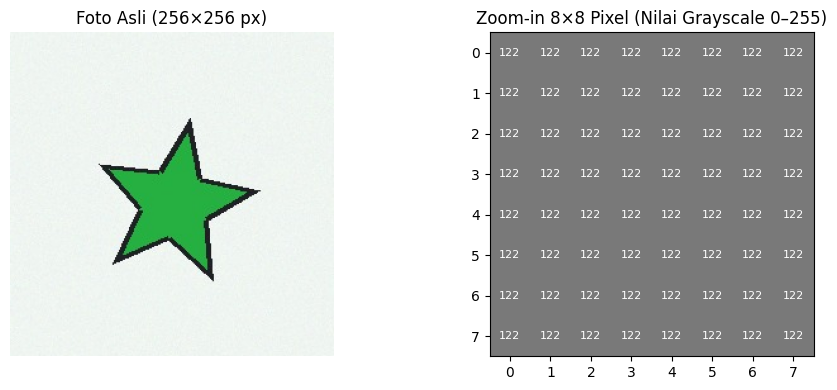

In [2]:
all_jpgs = sorted(DATA_DIR.rglob("*.jpg"))
assert len(all_jpgs) > 0, f"Tidak ditemukan file .jpg di {DATA_DIR}"
sample_img_path = all_jpgs[0]

# Buka gambar dengan PIL dan konversi ke format RGB standar
img_raw = Image.open(sample_img_path).convert("RGB")
arr_raw = np.array(img_raw)

print("File contoh :", sample_img_path.name)
print("Ukuran (W,H):", img_raw.size)
print("Shape array :", arr_raw.shape, "-> (Tinggi, Lebar, Channel)")
print("Tipe data   :", arr_raw.dtype)
print("Min / Max   :", int(arr_raw.min()), "/", int(arr_raw.max()))

# Visualisasikan foto asli dan zoom-in patch 8x8 di bagian tengah
h, w, _ = arr_raw.shape
cy, cx = h // 2, w // 2
patch_8x8 = arr_raw[cy - 4 : cy + 4, cx - 4 : cx + 4]
patch_gray = cv2.cvtColor(patch_8x8, cv2.COLOR_RGB2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(arr_raw)
axes[0].set_title(f"Foto Asli ({w}×{h} px)")
axes[0].axis("off")

axes[1].imshow(patch_gray, cmap="gray", vmin=0, vmax=255)
for r in range(8):
    for c in range(8):
        val = int(patch_gray[r, c])
        axes[1].text(c, r, str(val), ha="center", va="center",
                     color="white" if val < 128 else "black", fontsize=8)
axes[1].set_title("Zoom-in 8×8 Pixel (Nilai Grayscale 0–255)")
axes[1].set_xticks(range(8))
axes[1].set_yticks(range(8))
plt.tight_layout()
plt.show()

### Latihan 1: Membaca Dimensi & Nilai RGB Satu Pixel
Ambil dimensi `(img_h, img_w, img_c)` dari `arr_raw.shape` dan baca nilai `[R, G, B]` tepat di pixel tengah `(img_h // 2, img_w // 2)`.

In [3]:
img_h, img_w, img_c = arr_raw.shape
center_rgb = arr_raw[img_h // 2, img_w // 2]

assert img_c == 3, "Gambar RGB harus memiliki 3 channel"
assert len(center_rgb) == 3, "Nilai 1 pixel RGB harus berisi 3 angka [R, G, B]"
print(f"Dimensi: {img_h}×{img_w}×{img_c} | RGB pixel tengah: {center_rgb.tolist()}")
print("Cek Langkah 1 lolos!")

Dimensi: 256×256×3 | RGB pixel tengah: [38, 176, 65]
Cek Langkah 1 lolos!


---
## Langkah 2 (6 menit): Memisahkan *RGB Channels* & Mengubah ke *Grayscale*

Gambar berwarna sebenarnya adalah **3 lembar matriks yang ditumpuk**:
- `arr_raw[:, :, 0]` → Channel **Red**
- `arr_raw[:, :, 1]` → Channel **Green**
- `arr_raw[:, :, 2]` → Channel **Blue**

Jika kita hanya butuh **bentuk & terang-gelap** (misalnya untuk menghitung *brightness*, *contrast*, atau *edge density*), kita meringkas 3 channel tersebut menjadi 1 channel **Grayscale** berdimensi `(Tinggi, Lebar)`.

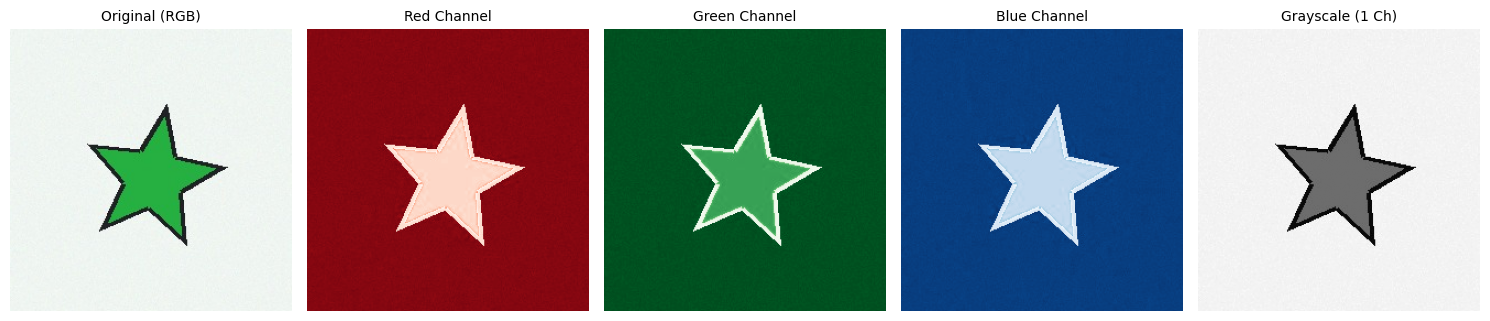

Cek Langkah 2 lolos!


In [4]:
# 2A. Pisahkan masing-masing channel R, G, B
r_ch = arr_raw[:, :, 0]
g_ch = arr_raw[:, :, 1]
b_ch = arr_raw[:, :, 2]

# 2B. Ubah gambar RGB menjadi Grayscale (1 channel)
gray_arr = cv2.cvtColor(arr_raw, cv2.COLOR_RGB2GRAY)

assert r_ch.shape == (img_h, img_w)
assert gray_arr.ndim == 2 and gray_arr.shape == (img_h, img_w), "Grayscale harus 2D (Tinggi, Lebar)"

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
panels = [
    (arr_raw, None, "Original (RGB)"),
    (r_ch, "Reds", "Red Channel"),
    (g_ch, "Greens", "Green Channel"),
    (b_ch, "Blues", "Blue Channel"),
    (gray_arr, "gray", "Grayscale (1 Ch)"),
]
for ax, (img_data, cmap, title) in zip(axes, panels):
    ax.imshow(img_data, cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Cek Langkah 2 lolos!")

---
## Langkah 3 (8 menit): *Image Processing* — *Resize*, *Aspect Ratio* & *Normalization*

Sebelum masuk ke model Deep Learning, foto mentah harus melewati 2 perapihan utama:
1. **Menyamakan Ukuran Tanpa Gepeng (*Letterbox Padding*):**  
   Model membutuhkan ukuran seragam (`224 × 224`). Jika foto persegi panjang langsung di-`resize((224, 224))`, objeknya menjadi **gepeng (*distorted*)**. Dengan *Letterbox Padding*, foto diperkecil proporsional lalu sisa ruangnya diisi *padding* abu-abu netral.
2. **Normalization (`0–255` → `0.0–1.0`):**  
   Angka `0–255` terlalu besar dan membuat proses belajar AI tidak stabil. Kita ubah tipenya ke `float32` lalu dibagi `255.0`.

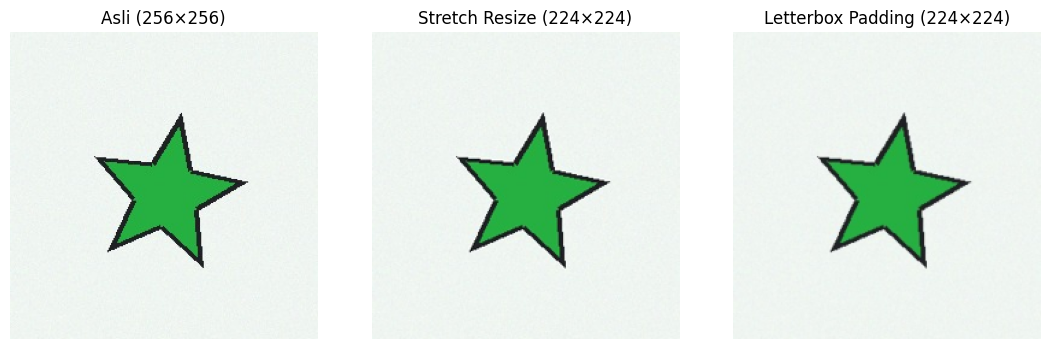

Sebelum normalisasi: dtype=uint8, min=2, max=252
Sesudah normalisasi: dtype=float32, min=0.0078, max=0.9882
Cek Langkah 3 lolos!


In [5]:
def resize_letterbox(im: Image.Image, target_size: int = IMG_SIZE, fill=(128, 128, 128)) -> Image.Image:
    """Ubah ukuran gambar ke target_size x target_size sambil menjaga aspect ratio dengan padding."""
    w, h = im.size
    scale = target_size / max(w, h)
    new_w, new_h = int(round(w * scale)), int(round(h * scale))
    resized = im.resize((new_w, new_h), Image.Resampling.BILINEAR)
    canvas = Image.new("RGB", (target_size, target_size), fill)
    canvas.paste(resized, ((target_size - new_w) // 2, (target_size - new_h) // 2))
    return canvas


# Bandingkan resize langsung (stretch) vs letterbox padding
img_stretch = img_raw.resize((IMG_SIZE, IMG_SIZE))
img_letterbox = resize_letterbox(img_raw, IMG_SIZE)

# Normalization: uint8 [0, 255] -> float32 [0.0, 1.0]
arr_u8 = np.array(img_letterbox)
arr_norm = arr_u8.astype(np.float32) / 255.0

assert img_letterbox.size == (IMG_SIZE, IMG_SIZE), "Ukuran output harus (224, 224)"
assert arr_norm.shape == (IMG_SIZE, IMG_SIZE, 3), "Shape harus (224, 224, 3)"
assert arr_norm.dtype == np.float32, "Dtype harus float32"
assert 0.0 <= arr_norm.min() and arr_norm.max() <= 1.0, "Nilai harus berada di [0.0, 1.0]"

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].imshow(img_raw)
axes[0].set_title(f"Asli ({img_raw.size[0]}×{img_raw.size[1]})")
axes[1].imshow(img_stretch)
axes[1].set_title(f"Stretch Resize ({IMG_SIZE}×{IMG_SIZE})")
axes[2].imshow(img_letterbox)
axes[2].set_title(f"Letterbox Padding ({IMG_SIZE}×{IMG_SIZE})")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Sebelum normalisasi: dtype={arr_u8.dtype}, min={arr_u8.min()}, max={arr_u8.max()}")
print(f"Sesudah normalisasi: dtype={arr_norm.dtype}, min={arr_norm.min():.4f}, max={arr_norm.max():.4f}")
print("Cek Langkah 3 lolos!")

---
## Langkah 4 (10 menit): Mengatasi 3 Jebakan Tersembunyi Kamera HP

Sebelum menganalisis seluruh koleksi foto, kita wajib membersihkan data dari **3 jebakan klasik**:
1. **Jebakan #1 — *EXIF Orientation*:** Kamera HP sering menyimpan foto miring lalu hanya menulis catatan rotasi di metadata EXIF. Gunakan `ImageOps.exif_transpose()` agar piksel benar-benar tegak.
2. **Jebakan #2 — *Corrupted Files*:** Foto yang gagal terunduh atau rusak dapat menghentikan training di tengah jalan. Cek integritasnya dengan `im.verify()`.
3. **Jebakan #3 — *Duplicate Images*:** Foto kembar yang masuk ke *Train* dan *Test* menyebabkan ***data leakage*** (AI sekadar menghafal). Deteksi dengan *sidik jari digital* (`SHA-256` hash).

In [6]:
# 4A. Fungsi membuka gambar dengan koreksi EXIF orientation
def load_image_exif_safe(path: Path) -> Image.Image:
    """Membuka gambar dan menerapkan koreksi orientasi EXIF secara otomatis."""
    with Image.open(path) as im:
        im_fixed = ImageOps.exif_transpose(im)
        return im_fixed.convert("RGB")


# 4B. Fungsi mengecek integritas file gambar
def check_image_integrity(path: Path) -> tuple[bool, int, int, str]:
    """Mengembalikan (is_valid, width, height, error_msg)."""
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im2:
            im2 = ImageOps.exif_transpose(im2)
            w, h = im2.size
        return True, int(w), int(h), ""
    except Exception as exc:
        return False, 0, 0, str(exc)


# 4C. Fungsi menghitung SHA-256 hash file untuk mendeteksi duplikat
def compute_sha256(path: Path, chunk_size: int = 8192) -> str:
    """Menghitung SHA-256 hex digest dari sebuah file."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(chunk_size):
            h.update(chunk)
    return h.hexdigest()


# Uji pada seluruh foto di DATA_DIR
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
image_files = sorted([p for p in DATA_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS])

records = []
for p in image_files:
    rel = p.relative_to(DATA_DIR)
    cls_name = rel.parts[0] if len(rel.parts) >= 2 else "unknown"
    cond = rel.parts[1] if len(rel.parts) >= 3 else "unknown"
    is_valid, w, h, err = check_image_integrity(p)
    sha = compute_sha256(p) if is_valid else ""
    records.append({
        "rel_path": str(rel).replace("\\", "/"),
        "class": cls_name,
        "condition": cond,
        "width": w,
        "height": h,
        "is_valid": is_valid,
        "error": err,
        "sha256": sha,
        "abs_path": str(p),
    })

df_audit = pd.DataFrame(records)
df_valid = df_audit[df_audit["is_valid"]].copy()
df_valid["is_duplicate"] = df_valid.duplicated(subset=["sha256"], keep="first")
df_audit["is_duplicate"] = df_audit["sha256"].isin(
    df_valid.loc[df_valid["is_duplicate"], "sha256"]
) & df_audit["rel_path"].isin(df_valid.loc[df_valid["is_duplicate"], "rel_path"])

n_corrupted = int((~df_audit["is_valid"]).sum())
n_dupes = int(df_valid["is_duplicate"].sum())

assert len(df_audit) > 0, "Audit DataFrame kosong!"
assert len(compute_sha256(sample_img_path)) == 64, "SHA-256 hex harus 64 karakter"

print(f"Total file dipindai : {len(df_audit)}")
print(f"Valid               : {len(df_valid)}")
print(f"Corrupted           : {n_corrupted}")
print(f"Duplicate (SHA-256) : {n_dupes}")
print("Cek Langkah 4 lolos!")

Total file dipindai : 120
Valid               : 119
Corrupted           : 1
Duplicate (SHA-256) : 1
Cek Langkah 4 lolos!


---
## Langkah 5 (12 menit): EDA Kesehatan Dataset (*Class Balance*, *Brightness*, *Contrast* & *Edge Density*)

Sekarang kita periksa **kesehatan dataset** secara deskriptif seperti di slide:
1. ***Class Balance*:** Apakah jumlah foto per kelas seimbang? Jika timpang, AI cenderung menebak kelas yang paling banyak.
2. ***Brightness* (`np.mean`):** Rata-rata kecerahan piksel (`0–255`).
3. ***Contrast* (`np.std`):** Simpangan baku kecerahan — seberapa kontras terang vs gelapnya.
4. ***Edge Density* (`cv2.Canny`):** Persentase piksel garis tepi. Latar **polos** memiliki *edge density* rendah; latar **ramai** penuh tekstur memiliki *edge density* jauh lebih tinggi.

Distribusi jumlah foto per kelas & kondisi:
condition  polos  ramai
class                  
bintang       12     12
heksagon      12     12
lingkaran     12     12
persegi       12     12
segitiga      12     11


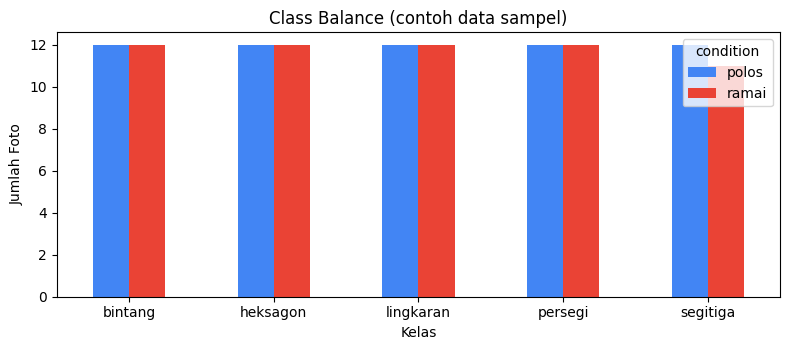

In [7]:
# 5A. Visualisasi Class Balance per kelas & kondisi
ct = pd.crosstab(df_valid["class"], df_valid["condition"])
print("Distribusi jumlah foto per kelas & kondisi:")
display(ct) if "display" in globals() else print(ct)

ax = ct.plot(kind="bar", figsize=(8, 3.6), color=["#4285F4", "#EA4335"])
ax.set_title(f"Class Balance ({DATA_LABEL})")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah Foto")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
# 5B. Hitung Brightness, Contrast, dan Edge Density untuk setiap foto valid
def compute_image_metrics(path: Path) -> tuple[float, float, float]:
    """Hitung (brightness, contrast, edge_density) dari gambar grayscale."""
    im = load_image_exif_safe(path)
    gray = np.array(im.convert("L"))
    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))
    edges = cv2.Canny(gray, 100, 200)
    edge_density = float(np.mean(edges > 0))
    return brightness, contrast, edge_density


metrics = [compute_image_metrics(Path(p)) for p in df_valid["abs_path"]]
df_valid[["brightness", "contrast", "edge_density"]] = pd.DataFrame(metrics, index=df_valid.index)

assert df_valid["brightness"].between(0, 255).all()
assert (df_valid["contrast"] >= 0).all()
assert df_valid["edge_density"].between(0, 1).all()
print("Cek Langkah 5 lolos! Contoh 5 baris hasil metrik:")
print(df_valid[["rel_path", "condition", "brightness", "contrast", "edge_density"]].head().to_string(index=False))

Cek Langkah 5 lolos! Contoh 5 baris hasil metrik:
                          rel_path condition  brightness  contrast  edge_density
bintang/polos/bintang_polos_01.jpg     polos  229.909775 43.772527      0.013962
bintang/polos/bintang_polos_02.jpg     polos  232.213120 40.134723      0.012283
bintang/polos/bintang_polos_03.jpg     polos  227.881851 46.099350      0.015106
bintang/polos/bintang_polos_04.jpg     polos  225.046600 46.745915      0.015213
bintang/polos/bintang_polos_05.jpg     polos  229.768646 42.996395      0.014771


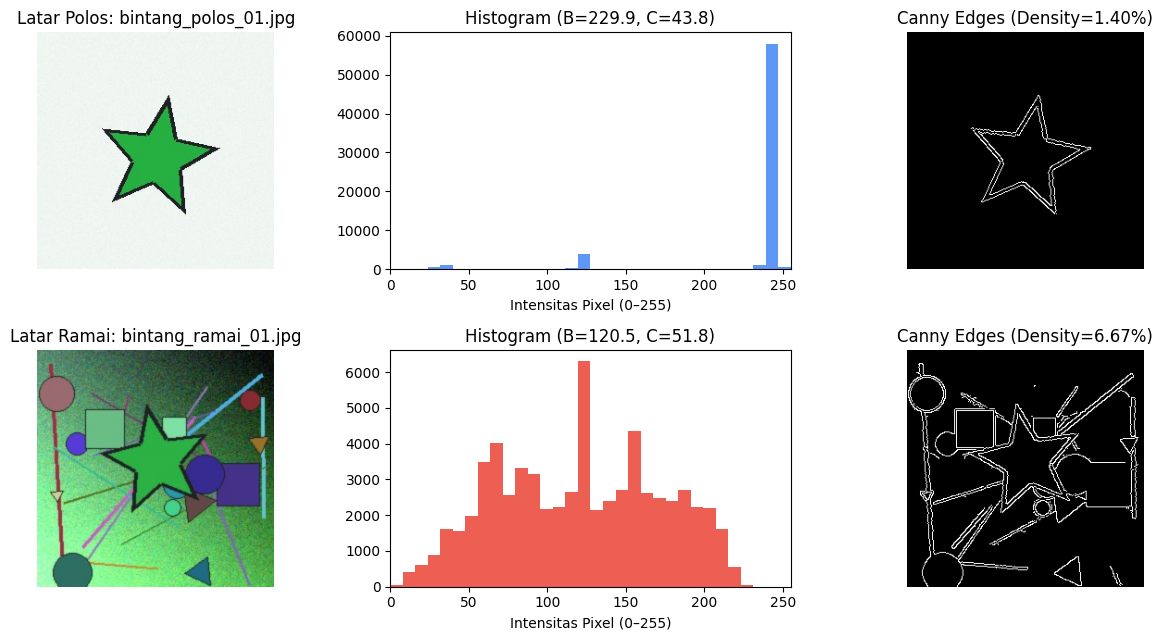

In [9]:
# 5C. Visualisasi Histogram Intensitas & Peta Tepi Canny: Polos vs Ramai
sample_polos = df_valid[df_valid["condition"] == "polos"].iloc[0] if (df_valid["condition"] == "polos").any() else df_valid.iloc[0]
sample_ramai = df_valid[df_valid["condition"] == "ramai"].iloc[0] if (df_valid["condition"] == "ramai").any() else df_valid.iloc[-1]

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for row, (label, row_data) in enumerate([("Latar Polos", sample_polos), ("Latar Ramai", sample_ramai)]):
    im_ex = load_image_exif_safe(Path(row_data["abs_path"]))
    gray_ex = np.array(im_ex.convert("L"))
    edges_ex = cv2.Canny(gray_ex, 100, 200)

    axes[row, 0].imshow(im_ex)
    axes[row, 0].set_title(f"{label}: {Path(row_data['rel_path']).name}")
    axes[row, 0].axis("off")

    axes[row, 1].hist(gray_ex.ravel(), bins=32, range=(0, 255), color="#4285F4" if row == 0 else "#EA4335", alpha=0.85)
    axes[row, 1].set_title(f"Histogram (B={row_data['brightness']:.1f}, C={row_data['contrast']:.1f})")
    axes[row, 1].set_xlim(0, 255)
    axes[row, 1].set_xlabel("Intensitas Pixel (0–255)")

    axes[row, 2].imshow(edges_ex, cmap="gray")
    axes[row, 2].set_title(f"Canny Edges (Density={row_data['edge_density']*100:.2f}%)")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.show()

---
## Langkah 6 (8 menit): Bandingkan *Polos vs Ramai*, Simpan Laporan Audit & *Mini-Challenge*

Terakhir, kita rangkum perbandingan seluruh foto **Polos vs Ramai** dalam tabel dan **Boxplot**, lalu simpan hasil audit ke folder `results/` agar siap dipakai pada pertemuan berikutnya.

Ringkasan EDA (contoh data sampel):
          brightness                    contrast                   \
               count      mean      std    count     mean     std   
condition                                                           
polos             60  228.1104   6.1898       60  45.2098  8.7442   
ramai             59  127.2126  10.8331       59  54.6922  4.9084   

          edge_density                  
                 count    mean     std  
condition                               
polos               60  0.0121  0.0019  
ramai               59  0.0853  0.0220  


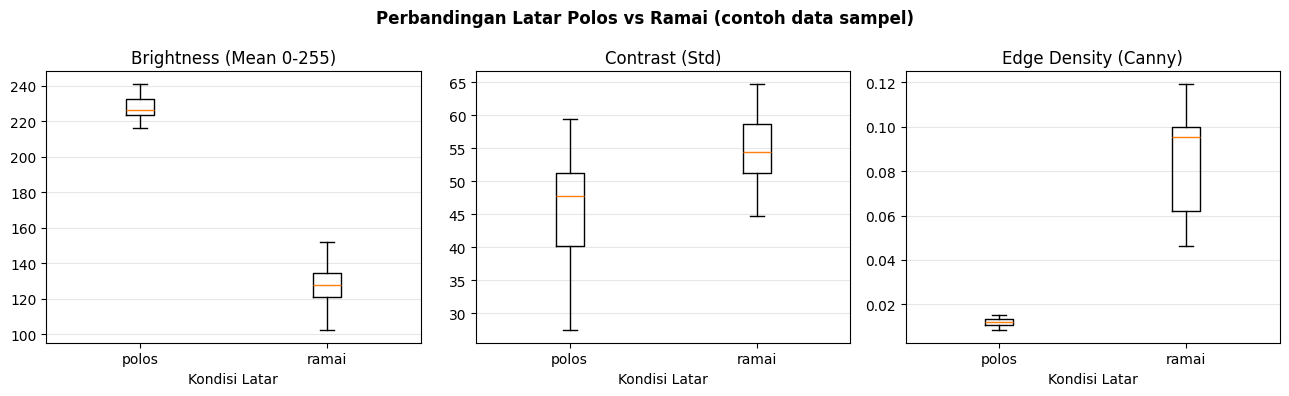

Tersimpan: p01_audit_metadata.csv, p01_eda_summary.csv, p01_eda_polos_vs_ramai.png di ..\..\results


In [10]:
summary = (
    df_valid.groupby("condition")[["brightness", "contrast", "edge_density"]]
    .agg(["count", "mean", "std"])
    .round(4)
)
print(f"Ringkasan EDA ({DATA_LABEL}):")
print(summary)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title in zip(
    axes,
    ["brightness", "contrast", "edge_density"],
    ["Brightness (Mean 0-255)", "Contrast (Std)", "Edge Density (Canny)"],
):
    groups = [g[col].values for _, g in df_valid.groupby("condition")]
    labels = [name for name, _ in df_valid.groupby("condition")]
    ax.boxplot(groups, tick_labels=labels)
    ax.set_title(title)
    ax.set_xlabel("Kondisi Latar")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(f"Perbandingan Latar Polos vs Ramai ({DATA_LABEL})", fontsize=12, fontweight="bold")
plt.tight_layout()
plot_path = RESULTS_DIR / "p01_eda_polos_vs_ramai.png"
fig.savefig(plot_path, dpi=150)
plt.show()

# Simpan CSV audit & summary
audit_cols = ["rel_path", "class", "condition", "width", "height", "is_valid", "is_duplicate", "sha256"]
df_audit_out = df_audit[audit_cols].merge(
    df_valid[["rel_path", "brightness", "contrast", "edge_density"]],
    on="rel_path",
    how="left",
)
audit_csv = RESULTS_DIR / "p01_audit_metadata.csv"
summary_csv = RESULTS_DIR / "p01_eda_summary.csv"
df_audit_out.to_csv(audit_csv, index=False)
summary.to_csv(summary_csv)

assert audit_csv.exists() and summary_csv.exists() and plot_path.exists()
print(f"Tersimpan: {audit_csv.name}, {summary_csv.name}, {plot_path.name} di {RESULTS_DIR}")

### Mini-Challenge & 3 Temuan Utama
Diskusikan dan jawab 3 pertanyaan berikut berdasarkan hasil EDA Anda:
1. Berapa jumlah total foto yang valid, berapa yang *corrupted*, dan apakah ada *duplicate images*?
2. Bandingkan nilai rata-rata **Edge Density** pada latar **polos** vs **ramai** — mengapa latar ramai berisiko mengganggu model AI jika data latih hanya berisi foto polos?
3. Setelah ukuran diseragamkan ke `224 × 224` dan dinormalisasi ke `[0.0, 1.0]`, langkah apa yang harus kita lakukan di pertemuan berikutnya sebelum melatih model?

*(Catatan metodologi: EDA pada sesi ini bersifat deskriptif; pembagian `Train / Val / Test` dan pencegahan data leakage secara penuh dilakukan pada sesi splitting dataset).*